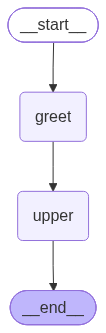

{'name': 'ricejson', 'greeting': 'HELLO, RICEJSON'}

In [4]:
# 导包
from typing import TypedDict, Annotated

from IPython.core.display import Image
from langgraph.constants import START, END
from langgraph.graph import StateGraph

# 定义 State
class GreetingState(TypedDict):
    name: str
    greeting: str
# 定义 Node
## 生成问候语节点
def greeting_node(state: GreetingState) -> dict:
    greeting = f"hello, {state['name']}"
    return {"greeting": greeting}

## 问候语转大写节点
def greeting_upper_node(state: GreetingState) -> dict:
    greeting_upper = state['greeting'].upper()
    return {"greeting": greeting_upper}
# 构建 Graph
graph_builder = StateGraph(GreetingState)
graph_builder.add_node("greet", greeting_node)
graph_builder.add_node("upper", greeting_upper_node)
graph_builder.add_edge(START, "greet")
graph_builder.add_edge("greet", "upper")
graph_builder.add_edge("upper", END)
graph = graph_builder.compile()
# 生成图结构
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))
# 运行 Graph
name = input("What is your name? ")
graph.invoke({"name": name})

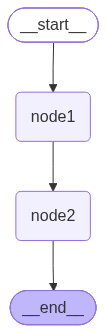

{'value': '2'}

In [5]:
# 默认 Reducer 演示
from typing import TypedDict
from langgraph.graph import StateGraph
from langgraph.constants import START, END

# 定义State
class DefaultReducerState(TypedDict):
    value: str

# 定义Node1
def node1(state: DefaultReducerState) -> dict:
    return {"value": "1"}

# 定义Node2
def node2(state: DefaultReducerState) -> dict:
    return {"value": "2"}

# 构建Graph
graph_builder = StateGraph(DefaultReducerState)
graph_builder.add_node("node1", node1)
graph_builder.add_node("node2", node2)
graph_builder.add_edge(START, "node1")
graph_builder.add_edge("node1", "node2")
graph_builder.add_edge("node2", END)
graph = graph_builder.compile()
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))
# 执行Graph
graph.invoke({})

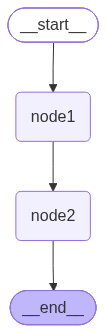

{'value': '12'}

In [6]:
# 自定义 Reducer
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph
from langgraph.constants import START, END

# 定义reducer
def add_reducer(old, new):
    return old + new

# 定义State
class SelfReducerState(TypedDict):
    value: Annotated[str, add_reducer]

# 定义Node1
def node1(state: SelfReducerState) -> dict:
    return {"value": "1"}

# 定义Node2
def node2(state: SelfReducerState) -> dict:
    return {"value": "2"}
# 定义Graph
graph_builder = StateGraph(SelfReducerState)
graph_builder.add_node("node1", node1)
graph_builder.add_node("node2", node2)
graph_builder.add_edge(START, "node1")
graph_builder.add_edge("node1", "node2")
graph_builder.add_edge("node2", END)
graph = graph_builder.compile()
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))
# 运行Graph
graph.invoke({})